In [1]:
#import the libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings
warnings.filterwarnings('ignore')


In [2]:
# Load the dataset
df = pd.read_csv('/kaggle/input/sentiment-analysis-for-mental-health/Combined Data.csv')

# Display the first few rows
df.head(10)


,Unnamed: 0,statement,status
0,0,oh my gosh,Anxiety
1,1,"trouble sleeping, confused mind, restless hear...",Anxiety
2,2,"All wrong, back off dear, forward doubt. Stay ...",Anxiety
3,3,I've shifted my focus to something else but I'...,Anxiety
4,4,"I'm restless and restless, it's been a month n...",Anxiety
5,5,"every break, you must be nervous, like somethi...",Anxiety
6,6,"I feel scared, anxious, what can I do? And may...",Anxiety
7,7,Have you ever felt nervous but didn't know why?,Anxiety
8,8,"I haven't slept well for 2 days, it's like I'm...",Anxiety
9,9,"I'm really worried, I want to cry.",Anxiety


In [3]:
df.info()
df.describe(include='all')
df.isnull().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53043 entries, 0 to 53042
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  53043 non-null  int64 
 1   statement   52681 non-null  object
 2   status      53043 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.2+ MB


Unnamed: 0      0
statement     362
status          0
dtype: int64

In [4]:
# Drop the 'Unnamed: 0' column
df.drop(columns=['Unnamed: 0'], inplace=True)

# Drop rows where 'statement' is missing
df.dropna(subset=['statement'], inplace=True)

# Confirm changes
df.info()


<class 'pandas.core.frame.DataFrame'>
Index: 52681 entries, 0 to 53042
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   statement  52681 non-null  object
 1   status     52681 non-null  object
dtypes: object(2)
memory usage: 1.2+ MB


# Converts text to lowercase


In [5]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Download resources (only run once)
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()  # Lowercase
    text = re.sub(r'http\S+|www.\S+', '', text)  # Remove URLs
    text = re.sub(r'@\w+|#\w+', '', text)  # Remove mentions/hashtags
    text = re.sub(r'[^a-z\s]', '', text)  # Remove punctuation/numbers
    words = text.split()  # Tokenize
    words = [lemmatizer.lemmatize(word) for word in words if word not in stop_words]  # Lemmatize & remove stopwords
    return ' '.join(words)

# Apply to existing column
df['statement'] = df['statement'].apply(clean_text)

# Preview the cleaned text
df.head()


[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /usr/share/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /usr/share/nltk_data...


,statement,status
0,oh gosh,Anxiety
1,trouble sleeping confused mind restless heart ...,Anxiety
2,wrong back dear forward doubt stay restless re...,Anxiety
3,ive shifted focus something else im still worried,Anxiety
4,im restless restless month boy mean,Anxiety


## Number of samples and statuses

Total samples: 52681

Mental Health Status counts:
status
Normal                  16343
Depression              15404
Suicidal                10652
Anxiety                  3841
Bipolar                  2777
Stress                   2587
Personality disorder     1077
Name: count, dtype: int64


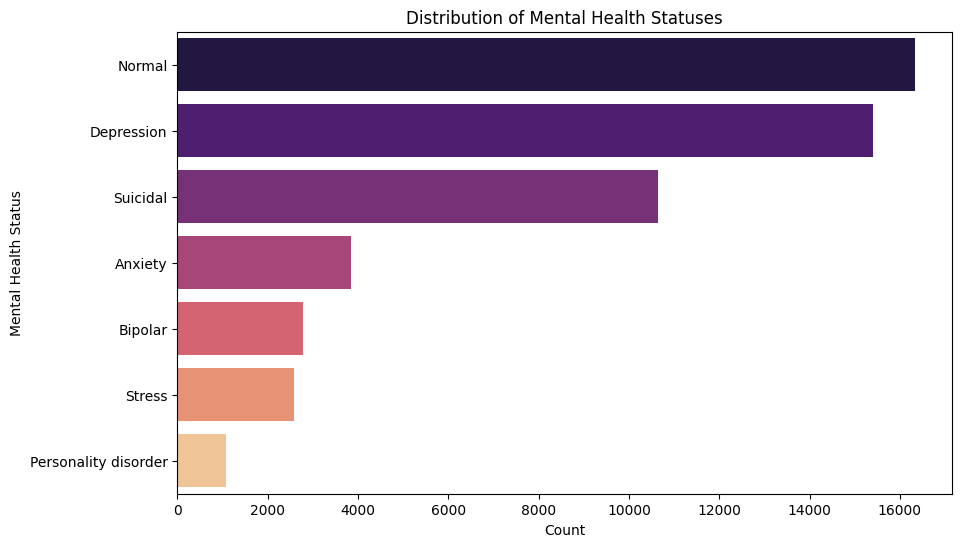

In [6]:

print(f"Total samples: {len(df)}")
print("\nMental Health Status counts:")
print(df['status'].value_counts())

# Plot distribution
plt.figure(figsize=(10,6))
sns.countplot(y='status', data=df, order=df['status'].value_counts().index, palette='magma')
plt.title("Distribution of Mental Health Statuses")
plt.xlabel('Count')
plt.ylabel('Mental Health Status')
plt.show()


## Plot word count distribution

         word_count    char_count
count  52681.000000  52681.000000
mean      51.512766    336.043792
std       74.117574    502.476507
min        0.000000      0.000000
25%        8.000000     49.000000
50%       29.000000    185.000000
75%       67.000000    437.000000
max     3780.000000  25289.000000


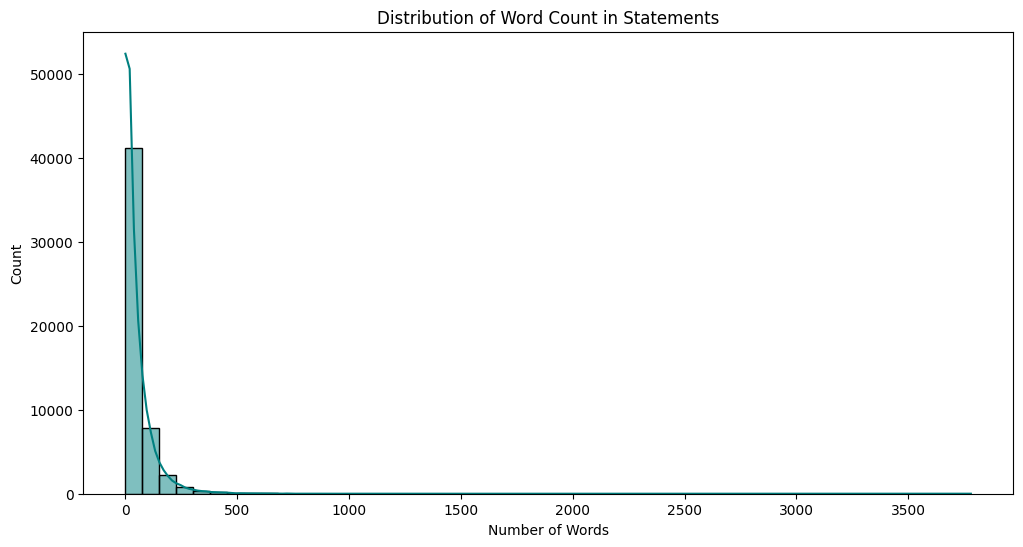

In [7]:
# Add word and char count columns
df['word_count'] = df['statement'].apply(lambda x: len(str(x).split()))
df['char_count'] = df['statement'].apply(lambda x: len(str(x)))

# Summary statistics for lengths
print(df[['word_count', 'char_count']].describe())


plt.figure(figsize=(12,6))
sns.histplot(df['word_count'], bins=50, kde=True, color='teal')
plt.title('Distribution of Word Count in Statements')
plt.xlabel('Number of Words')
plt.show()


In [8]:
df = df[df['word_count'] > 0].reset_index(drop=True)
print(f"After removing empty texts: {len(df)} samples left.")


After removing empty texts: 52527 samples left.


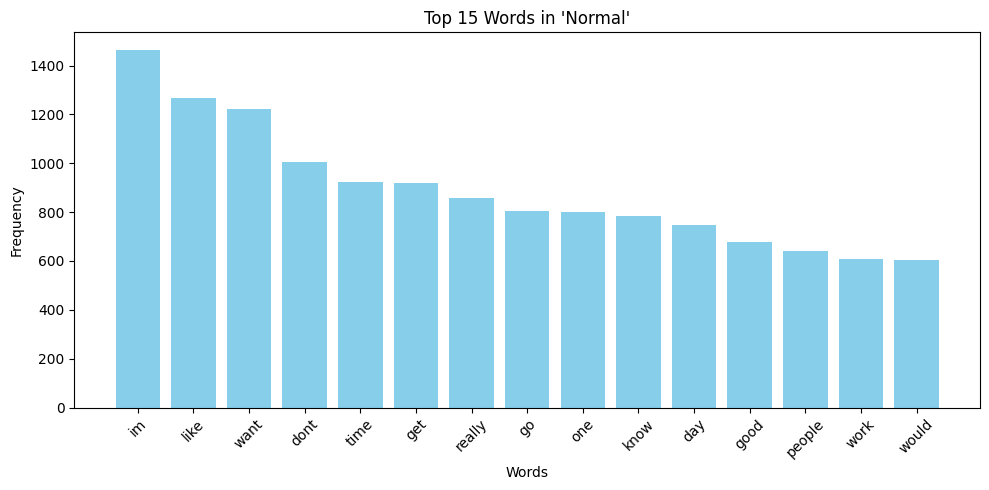

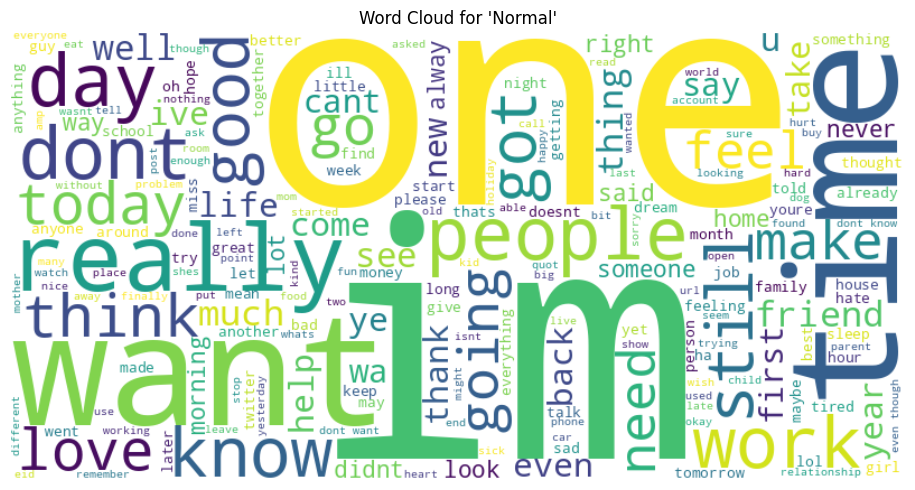

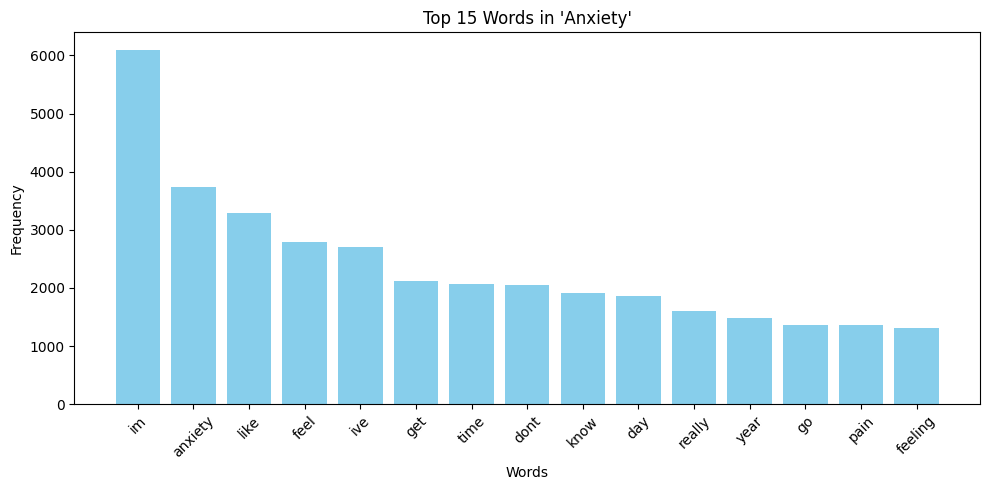

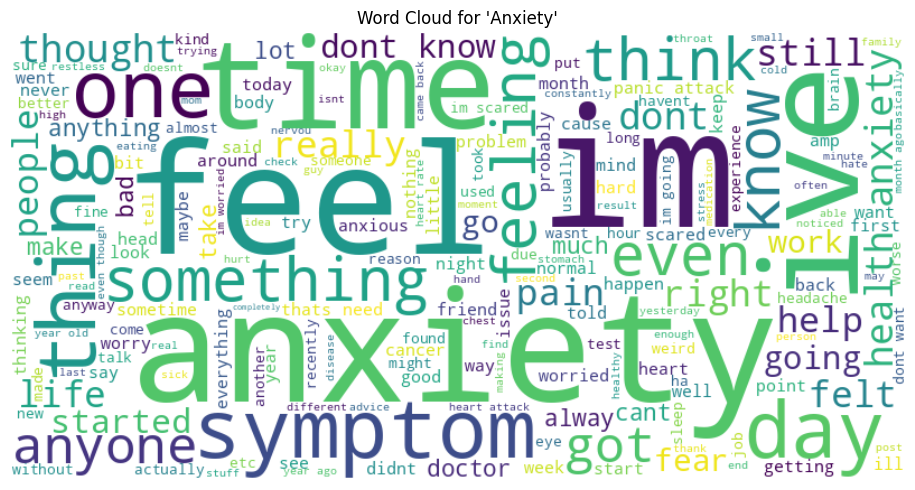

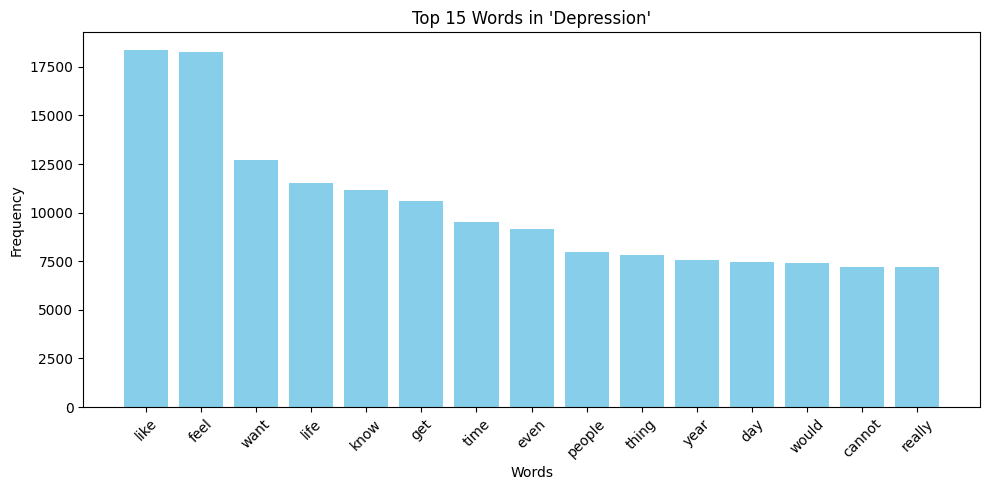

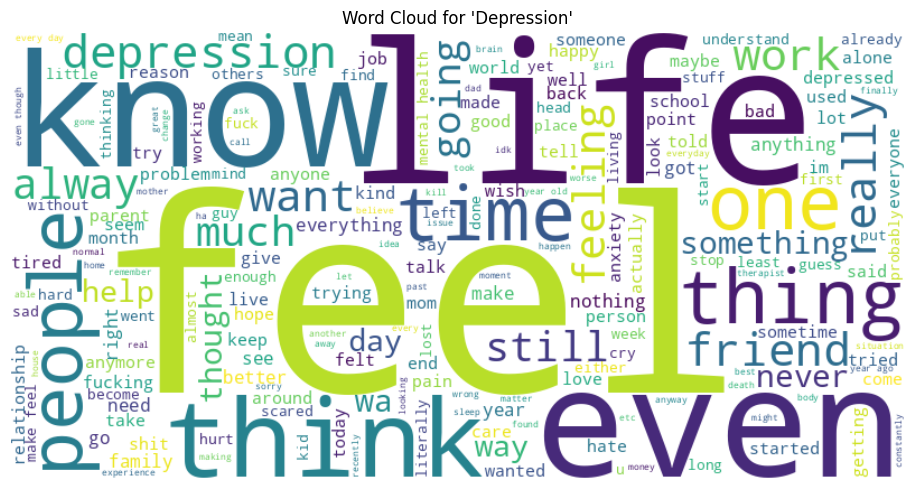

In [9]:
import matplotlib.pyplot as plt
from collections import Counter
from wordcloud import WordCloud
import pandas as pd

# Function to get top words for a given status
def get_top_words(status, n=15):
    texts = df[df['status'] == status]['statement']
    all_words = ' '.join(texts).split()
    common_words = Counter(all_words).most_common(n)
    return common_words

# Bar chart function
def plot_top_words_bar(status, n=15):
    common_words = get_top_words(status, n)
    words, counts = zip(*common_words)
    
    plt.figure(figsize=(10, 5))
    plt.bar(words, counts, color='skyblue')
    plt.title(f"Top {n} Words in '{status}'")
    plt.xticks(rotation=45)
    plt.xlabel('Words')
    plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()

# Word cloud function
def plot_wordcloud(status):
    text = ' '.join(df[df['status'] == status]['statement'])
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
    
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(f"Word Cloud for '{status}'")
    plt.tight_layout()
    plt.show()

# Plot for all statuses
for status in ['Normal', 'Anxiety', 'Depression']:
    plot_top_words_bar(status)
    plot_wordcloud(status)


# Preprocessing

In [10]:
# Define the classes you want to keep
selected_classes = ['Normal', 'Anxiety', 'Depression']

# Filter the dataframe
df = df[df['status'].isin(selected_classes)].reset_index(drop=True)

# Check the new class distribution
print(df['status'].value_counts())


status
Normal        16206
Depression    15395
Anxiety        3841
Name: count, dtype: int64


In [11]:
df.head()

,statement,status,word_count,char_count
0,oh gosh,Anxiety,2,7
1,trouble sleeping confused mind restless heart ...,Anxiety,7,50
2,wrong back dear forward doubt stay restless re...,Anxiety,9,58
3,ive shifted focus something else im still worried,Anxiety,8,49
4,im restless restless month boy mean,Anxiety,6,35


In [12]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['label'] = le.fit_transform(df['status'])

# Check mapping
print(dict(zip(le.classes_, le.transform(le.classes_))))

df.head()


{'Anxiety': 0, 'Depression': 1, 'Normal': 2}


,statement,status,word_count,char_count,label
0,oh gosh,Anxiety,2,7,0
1,trouble sleeping confused mind restless heart ...,Anxiety,7,50,0
2,wrong back dear forward doubt stay restless re...,Anxiety,9,58,0
3,ive shifted focus something else im still worried,Anxiety,8,49,0
4,im restless restless month boy mean,Anxiety,6,35,0


## SPILIT THE DATA 

In [13]:

from sklearn.model_selection import train_test_split  
from collections import Counter

# Step 1: 80% train+val, 20% test
X_temp, X_test, y_temp, y_test = train_test_split(
    df['statement'], df['label'],
    test_size=0.20,  # 20% test
    stratify=df['label'],
    random_state=42
)

# Step 2: split 80% into 70% train and 10% val
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.125,  # 10% of total data (0.125 * 80% ≈ 10%)
    stratify=y_temp,
    random_state=42
)

# Verify sizes
print(f"Train set: {len(X_train)} samples")
print(f"Validation set: {len(X_val)} samples")
print(f"Test set: {len(X_test)} samples")

# Check class distributions
print("Train set class distribution:", Counter(y_train))
print("Validation set class distribution:", Counter(y_val))
print("Test set class distribution:", Counter(y_test))


Train set: 24808 samples
Validation set: 3545 samples
Test set: 7089 samples
Train set class distribution: Counter({2: 11343, 1: 10776, 0: 2689})
Validation set class distribution: Counter({2: 1621, 1: 1540, 0: 384})
Test set class distribution: Counter({2: 3242, 1: 3079, 0: 768})


# Train Model

## DistilBert model

2026-07-18 10:24:32.435470: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1784370272.629462      20 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1784370272.686951      20 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Epoch 9: 100%|██████████| 1551/1551 [02:16<00:00, 11.35it/s, loss=0.000138]



Validation Set Accuracy: 95.15%


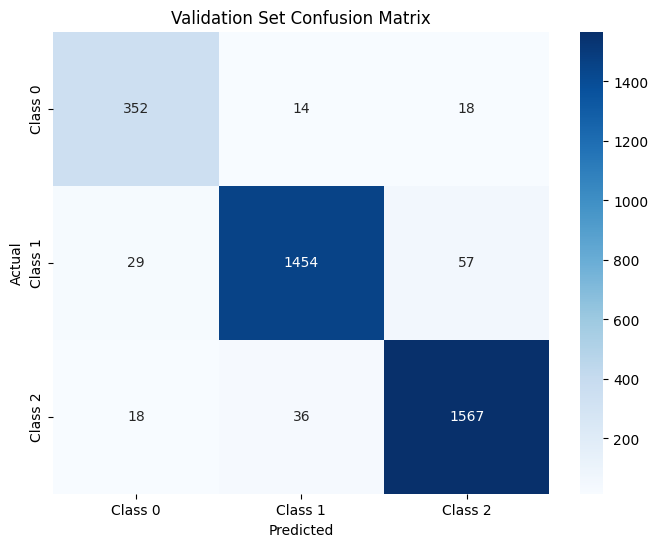


Validation Set Classification Report:
Accuracy: 95.15%
Precision (macro avg): 93.44%
Recall (macro avg): 94.25%
F1-score (macro avg): 93.83%

Validation Set AUC-ROC (macro avg): 98.91%


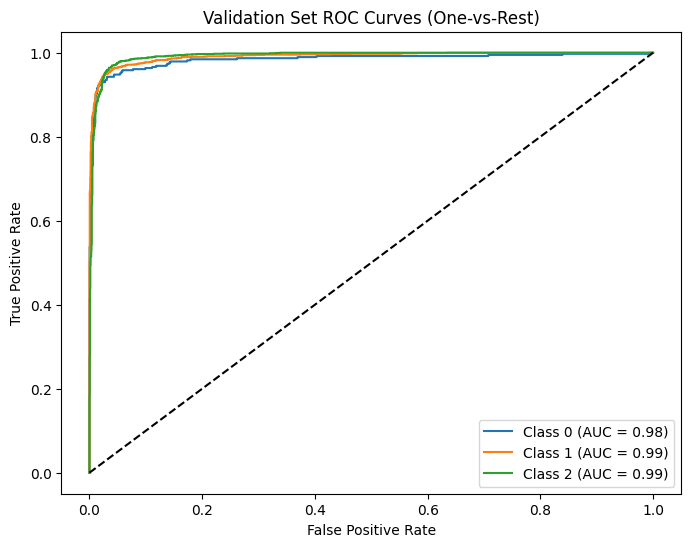


Test Set Accuracy: 95.33%


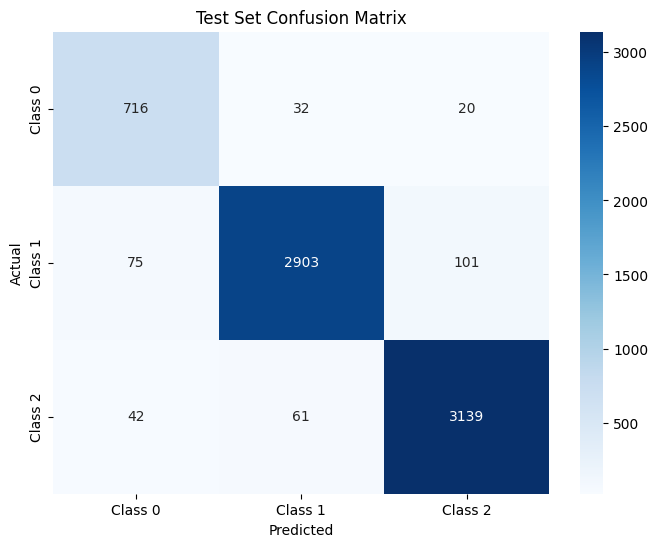


Test Set Classification Report:
Accuracy: 95.33%
Precision (macro avg): 93.05%
Recall (macro avg): 94.78%
F1-score (macro avg): 93.86%

Test Set AUC-ROC (macro avg): 99.17%


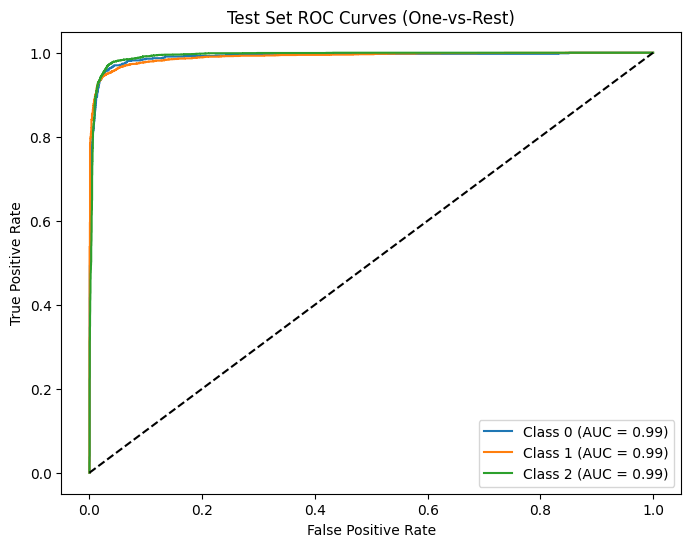

In [14]:
                

from transformers import DistilBertTokenizer, DistilBertForSequenceClassification    
from torch.optim import AdamW
from torch.utils.data import Dataset, DataLoader
import torch
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score, roc_curve
from sklearn.utils.class_weight import compute_class_weight
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
distilbert_acc = 0

# Tokenizer and Tokenization

tokenizer = DistilBertTokenizer.from_pretrained('distilbert-base-uncased')

def tokenize_fn(texts):
    return tokenizer(list(texts), padding=True, truncation=True, max_length=100, return_tensors='pt')

train_encodings = tokenize_fn(X_train)
val_encodings   = tokenize_fn(X_val)
test_encodings  = tokenize_fn(X_test)

y_train_tensor = torch.tensor(list(y_train))
y_val_tensor   = torch.tensor(list(y_val))
y_test_tensor  = torch.tensor(list(y_test))


# Dataset Class

class TextDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, idx):
        return {key: val[idx] for key, val in self.encodings.items()}, self.labels[idx]

train_dataset = TextDataset(train_encodings, y_train_tensor)
val_dataset   = TextDataset(val_encodings, y_val_tensor)
test_dataset  = TextDataset(test_encodings, y_test_tensor)


# DataLoaders

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=16)
test_loader  = DataLoader(test_dataset, batch_size=16)


# Model, Device, Loss, Optimizer

device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
model = DistilBertForSequenceClassification.from_pretrained('distilbert-base-uncased', num_labels=3)
model.to(device)

class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
weights = torch.tensor(class_weights, dtype=torch.float).to(device)
loss_fn = torch.nn.CrossEntropyLoss(weight=weights)
optimizer = AdamW(model.parameters(), lr=2e-5)


# Training Loop

model.train()
for epoch in range(10):
    loop = tqdm(train_loader, leave=True)
    for batch in loop:
        inputs, labels = batch
        inputs = {k: v.to(device) for k, v in inputs.items()}
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(**inputs)
        logits = outputs.logits
        loss = loss_fn(logits, labels)
        loss.backward()
        optimizer.step()

        loop.set_description(f"Epoch {epoch}")
        loop.set_postfix(loss=loss.item())


# Evaluation Function

def evaluate_model(loader, set_name="Set"):
    model.eval()
    all_preds = []
    all_labels = []
    all_probs = []

    with torch.no_grad():
        for batch in loader:
            inputs, labels = batch
            inputs = {k: v.to(device) for k, v in inputs.items()}
            labels = labels.to(device)

            outputs = model(**inputs)
            probs = torch.softmax(outputs.logits, dim=-1)
            preds = torch.argmax(outputs.logits, dim=-1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    all_labels_np = np.array(all_labels)
    all_preds_np  = np.array(all_preds)
    all_probs_np  = np.array(all_probs)

    # Accuracy
    acc = accuracy_score(all_labels_np, all_preds_np)
    print(f"\n{set_name} Accuracy: {acc*100:.2f}%")
    distilbert_acc = acc*100
    # Confusion Matrix
    cm = confusion_matrix(all_labels_np, all_preds_np)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Class 0', 'Class 1', 'Class 2'],
                yticklabels=['Class 0', 'Class 1', 'Class 2'])
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(f'{set_name} Confusion Matrix')
    plt.show()

    # Classification Report
    report = classification_report(all_labels_np, all_preds_np, target_names=['Class 0', 'Class 1', 'Class 2'], output_dict=True)
    print(f"\n{set_name} Classification Report:")
    print(f"Accuracy: {report['accuracy']*100:.2f}%")
    print(f"Precision (macro avg): {report['macro avg']['precision']*100:.2f}%")
    print(f"Recall (macro avg): {report['macro avg']['recall']*100:.2f}%")
    print(f"F1-score (macro avg): {report['macro avg']['f1-score']*100:.2f}%")

    # AUC-ROC
    if len(np.unique(all_labels_np)) > 2:
        auc_macro = roc_auc_score(all_labels_np, all_probs_np, multi_class='ovr', average='macro')
        print(f"\n{set_name} AUC-ROC (macro avg): {auc_macro*100:.2f}%")

        plt.figure(figsize=(8, 6))
        for i in range(3):
            fpr, tpr, _ = roc_curve(all_labels_np == i, all_probs_np[:, i])
            auc_class = roc_auc_score(all_labels_np == i, all_probs_np[:, i])
            plt.plot(fpr, tpr, label=f'Class {i} (AUC = {auc_class:.2f})')
        plt.plot([0, 1], [0, 1], 'k--')
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.title(f'{set_name} ROC Curves (One-vs-Rest)')
        plt.legend()
        plt.show()
    else:
        auc_binary = roc_auc_score(all_labels_np, all_probs_np[:, 1])
        print(f"\n{set_name} AUC-ROC: {auc_binary*100:.2f}%")


# Evaluate Validation and Test Sets

evaluate_model(val_loader, set_name="Validation Set")
evaluate_model(test_loader, set_name="Test Set")


## DistilTextClassifier-CNN-hybrid model

In [15]:
from transformers import DistilBertTokenizer, DistilBertModel              
from torch.optim import AdamW
from torch.utils.data import Dataset, DataLoader
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score
from tqdm import tqdm
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Initialize tokenizer
tokenizer = DistilBertTokenizer.from_pretrained('distilbert-base-uncased')

# Tokenize function 
def tokenize_fn(texts):
    return tokenizer(list(texts), padding=True, truncation=True, max_length=100, return_tensors='pt')

# Tokenize train, val, test
train_encodings = tokenize_fn(X_train)
val_encodings = tokenize_fn(X_val)
test_encodings = tokenize_fn(X_test)

# Convert labels to tensors
y_train_tensor = torch.tensor(list(y_train))
y_val_tensor = torch.tensor(list(y_val))
y_test_tensor = torch.tensor(list(y_test))

# Step 3: Create Dataset class
class TextDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, idx):
        return {key: val[idx] for key, val in self.encodings.items()}, self.labels[idx]

train_dataset = TextDataset(train_encodings, y_train_tensor)
val_dataset = TextDataset(val_encodings, y_val_tensor)
test_dataset = TextDataset(test_encodings, y_test_tensor)

# Define Hybrid Model
class HybridDistilBERTCNN(nn.Module):
    def __init__(self, num_classes=3):
        super(HybridDistilBERTCNN, self).__init__()
        
        # DistilBERT base model
        self.bert = DistilBertModel.from_pretrained('distilbert-base-uncased')
        
        # Freeze BERT layers (optional)
        # for param in self.bert.parameters():
        #     param.requires_grad = False
            
        # CNN layers
        self.conv1 = nn.Conv1d(in_channels=768, out_channels=256, kernel_size=3, padding=1)
        self.conv2 = nn.Conv1d(in_channels=256, out_channels=128, kernel_size=3, padding=1)
        self.pool = nn.MaxPool1d(kernel_size=2)
        
        # Dropout
        self.dropout = nn.Dropout(0.2)
        
        # Fully connected layers
        self.fc1 = nn.Linear(128 * 25, 64)  # 25 comes from max_length=100 / pool_size=2 twice
        self.fc2 = nn.Linear(64, num_classes)
        
    def forward(self, input_ids, attention_mask):
        # BERT output
        bert_output = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        hidden_state = bert_output.last_hidden_state  # (batch_size, seq_len, 768)
        
        # Permute for CNN (batch_size, channels, seq_len)
        cnn_input = hidden_state.permute(0, 2, 1)
        
        # CNN layers
        x = torch.relu(self.conv1(cnn_input))
        x = self.pool(x)
        x = torch.relu(self.conv2(x))
        x = self.pool(x)
        
        # Flatten
        x = x.view(x.size(0), -1)
        
        # Fully connected layers
        x = self.dropout(x)
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)
        
        return x

# Initialize model
model = HybridDistilBERTCNN(num_classes=3)
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
model.to(device)

# Setup training
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16)

# compute class weights to handle imbalance
class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
weights = torch.tensor(class_weights, dtype=torch.float).to(device)
loss_fn = torch.nn.CrossEntropyLoss(weight=weights)

optimizer = AdamW(model.parameters(), lr=2e-5)

# Training loop
model.train()
for epoch in range(10):
    loop = tqdm(train_loader, leave=True)
    for batch in loop:
        inputs, labels = batch
        input_ids = inputs['input_ids'].to(device)
        attention_mask = inputs['attention_mask'].to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(input_ids, attention_mask)
        loss = loss_fn(outputs, labels)
        loss.backward()
        optimizer.step()

        loop.set_description(f"Epoch {epoch}")
        loop.set_postfix(loss=loss.item())

#  Evaluation on validation set
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for batch in val_loader:
        inputs, labels = batch
        input_ids = inputs['input_ids'].to(device)
        attention_mask = inputs['attention_mask'].to(device)
        labels = labels.to(device)

        outputs = model(input_ids, attention_mask)
        preds = torch.argmax(outputs, dim=-1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

accuracy = accuracy_score(all_labels, all_preds)
print(f"Validation accuracy: {accuracy:.4f}")

Epoch 9: 100%|██████████| 1551/1551 [02:20<00:00, 11.05it/s, loss=4.73e-5]


Validation accuracy: 0.9487


## DistilTextClassifier-CNN-hybrid model test 

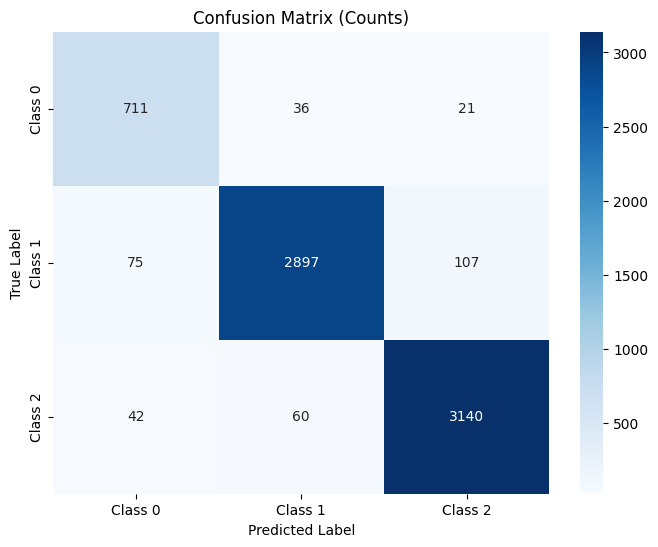


AUC-ROC Score (One-vs-Rest): 0.9916


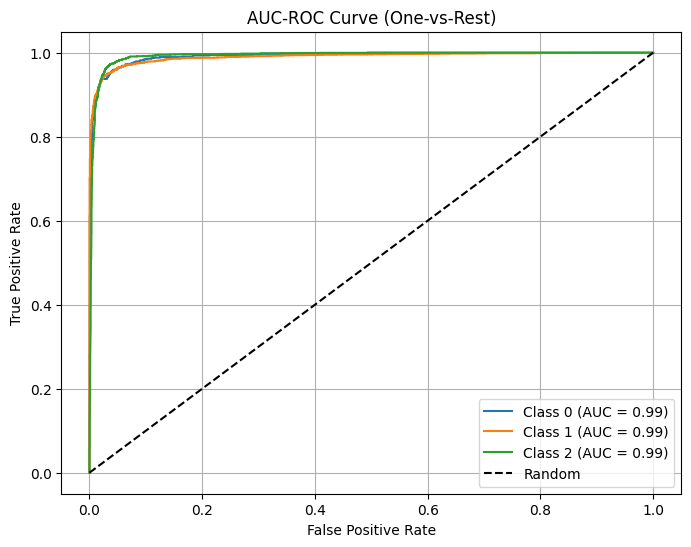


Classification Report (%):
             precision  recall f1-score      support
Class 0         85.87%  92.58%   89.10%   768.000000
Class 1         96.79%  94.09%   95.42%  3079.000000
Class 2         96.08%  96.85%   96.47%  3242.000000
accuracy        95.19%  95.19%   95.19%     0.951897
macro avg       92.92%  94.51%   93.66%  7089.000000
weighted avg    95.28%  95.19%   95.21%  7089.000000

Overall Accuracy: 95.19%

Per-class Rates (%):
         TP Rate (%)  FP Rate (%)  TN Rate (%)  FN Rate (%)
Class 0        92.58         1.85        98.15         7.42
Class 1        94.09         2.39        97.61         5.91
Class 2        96.85         3.33        96.67         3.15


In [16]:


from sklearn.metrics import confusion_matrix, roc_auc_score, classification_report, accuracy_score, roc_curve  
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import torch

#  Test Evaluation
model.eval()
all_preds = []
all_probs = []
all_labels = []

with torch.no_grad():
    for batch in test_dataset:
        inputs, labels = batch
        input_ids = inputs['input_ids'].unsqueeze(0).to(device)
        attention_mask = inputs['attention_mask'].unsqueeze(0).to(device)
        labels = labels.unsqueeze(0).to(device)

        outputs = model(input_ids, attention_mask)
        probs = torch.softmax(outputs, dim=1)
        preds = torch.argmax(outputs, dim=1)

        all_preds.append(preds.cpu().item())
        all_probs.append(probs.cpu().numpy()[0])
        all_labels.append(labels.cpu().item())

# Convert to numpy arrays
all_labels = np.array(all_labels)
all_preds = np.array(all_preds)
all_probs = np.array(all_probs)

# 1. Confusion Matrix (no %)
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Class 0', 'Class 1', 'Class 2'],
            yticklabels=['Class 0', 'Class 1', 'Class 2'])
plt.title('Confusion Matrix (Counts)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

# AUC-ROC Score
try:
    auc_roc = roc_auc_score(all_labels, all_probs, multi_class='ovr')
    print(f"\nAUC-ROC Score (One-vs-Rest): {auc_roc:.4f}")
except Exception as e:
    print(f"\nCould not compute AUC-ROC: {str(e)}")

#  AUC-ROC Curve for each class
fpr = dict()
tpr = dict()
for i in range(3):  # for each class
    fpr[i], tpr[i], _ = roc_curve(all_labels == i, all_probs[:, i])

plt.figure(figsize=(8, 6))
for i in range(3):
    plt.plot(fpr[i], tpr[i], label=f"Class {i} (AUC = {roc_auc_score(all_labels == i, all_probs[:, i]):.2f})")
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("AUC-ROC Curve (One-vs-Rest)")
plt.legend()
plt.grid(True)
plt.show()

#  Classification Report (with %)
report = classification_report(all_labels, all_preds, target_names=['Class 0', 'Class 1', 'Class 2'], output_dict=True)
report_df = pd.DataFrame(report).transpose()
for metric in ['precision', 'recall', 'f1-score']:
    report_df[metric] = report_df[metric].apply(lambda x: f"{x*100:.2f}%")
print("\nClassification Report (%):")
print(report_df)

# 4. Accuracy
accuracy = accuracy_score(all_labels, all_preds)
print(f"\nOverall Accuracy: {accuracy*100:.2f}%")

# 5. Per-class metrics
class_metrics = {}
for i in range(3):
    tp = cm[i, i]
    fp = cm[:, i].sum() - tp
    fn = cm[i, :].sum() - tp
    tn = cm.sum() - (tp + fp + fn)

    class_metrics[f'Class {i}'] = {
        'TP Rate (%)': tp / (tp + fn) * 100 if (tp + fn) > 0 else 0.0,
        'FP Rate (%)': fp / (fp + tn) * 100 if (fp + tn) > 0 else 0.0,
        'TN Rate (%)': tn / (tn + fp) * 100 if (tn + fp) > 0 else 0.0,
        'FN Rate (%)': fn / (fn + tp) * 100 if (fn + tp) > 0 else 0.0,
    }

print("\nPer-class Rates (%):")
print(pd.DataFrame(class_metrics).transpose().round(2))


In [17]:
hybrid_acc = accuracy * 100

## CNN Model

Epoch 1/60


I0000 00:00:1784373242.033130      20 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13287 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0
I0000 00:00:1784373244.736859      84 service.cc:148] XLA service 0x7f5578007ea0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1784373244.737572      84 service.cc:156]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1784373245.151310      84 cuda_dnn.cc:529] Loaded cuDNN version 90300


 45/776 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.3898 - loss: 1.0045

I0000 00:00:1784373247.301375      84 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


776/776 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.7804 - loss: 0.5286 - val_accuracy: 0.9162 - val_loss: 0.2491
Epoch 2/60
776/776 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9511 - loss: 0.1449 - val_accuracy: 0.9176 - val_loss: 0.2427
Epoch 3/60
776/776 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9707 - loss: 0.0895 - val_accuracy: 0.9238 - val_loss: 0.2938
Epoch 4/60
776/776 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9805 - loss: 0.0573 - val_accuracy: 0.9221 - val_loss: 0.2976
Epoch 5/60
776/776 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9872 - loss: 0.0418 - val_accuracy: 0.9173 - val_loss: 0.3367
Epoch 6/60
776/776 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9898 - loss: 0.0330 - val_accuracy: 0.9230 - val_loss: 0.3954
Epoch 7/60
776/776 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9903 - loss: 0.0301 - val_accuracy: 0.9159 - val_loss: 0.4071
Epoch 8/60
776/776 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9946 - loss: 0.0175 - val_accuracy: 0.9230 - val

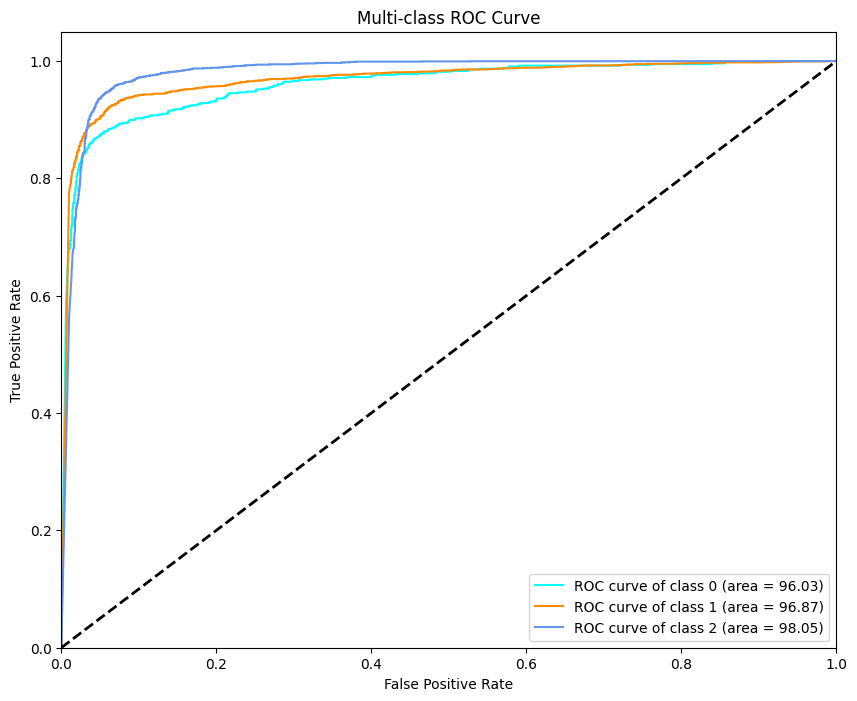

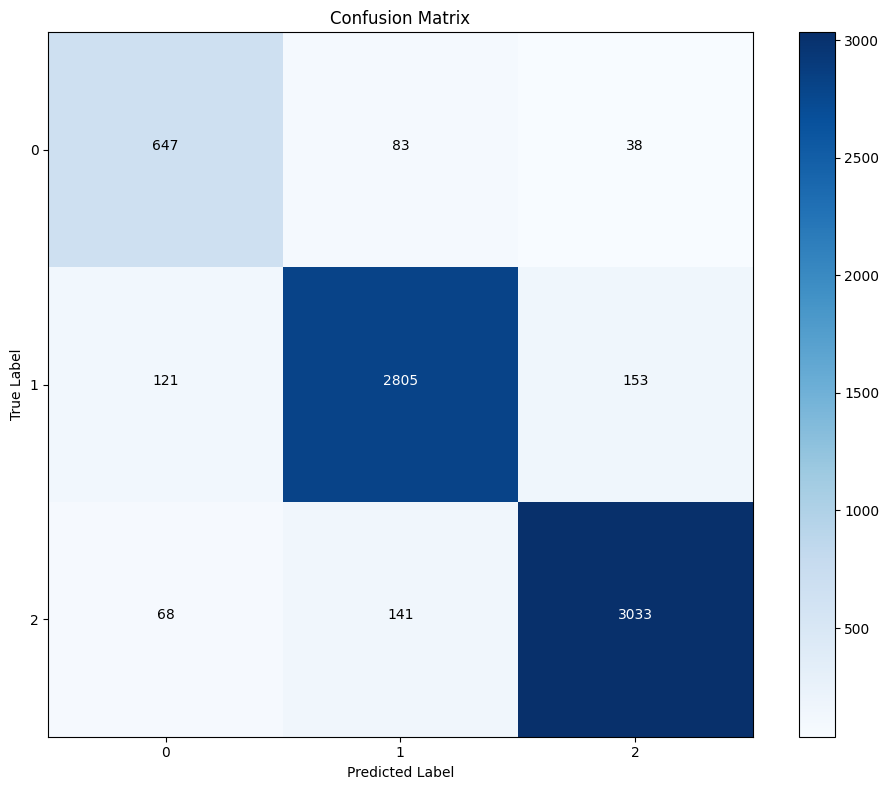

In [18]:

import tensorflow as tf    
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Conv1D, MaxPooling1D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (classification_report, confusion_matrix, 
                            roc_auc_score, roc_curve, auc, 
                            precision_score, recall_score, f1_score, accuracy_score)
from itertools import cycle
from sklearn.preprocessing import label_binarize

# Assuming X_train, y_train, X_val, y_val, X_test, y_test are already defined

# Hyperparameters
vocab_size = 10000
embed_dim = 128
max_len = 100
num_classes = len(set(y_train))

# Tokenization
tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len, padding='post')
X_val_pad = pad_sequences(X_val_seq, maxlen=max_len, padding='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len, padding='post')

# One-hot encode labels
y_train_cat = tf.keras.utils.to_categorical(y_train, num_classes)
y_val_cat = tf.keras.utils.to_categorical(y_val, num_classes)
y_test_cat = tf.keras.utils.to_categorical(y_test, num_classes)

# Calculate class weights
class_weights = compute_class_weight('balanced',
                                   classes=np.unique(y_train),
                                   y=y_train)
class_weights = dict(enumerate(class_weights))

# Model definition
model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=embed_dim, input_length=max_len),
    Conv1D(128, 3, activation='relu', padding='same'),
    MaxPooling1D(2),
    Conv1D(64, 3, activation='relu', padding='same'),
    MaxPooling1D(2),
    Flatten(),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dense(num_classes, activation='softmax')
])

# Compile model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Train with class weights
history = model.fit(X_train_pad, y_train_cat,
                    epochs=60,
                    batch_size=32,
                    validation_data=(X_val_pad, y_val_cat),
                    class_weight=class_weights)

# Predictions
y_pred = model.predict(X_test_pad)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_test_cat, axis=1)

# Calculate metrics
accuracy = accuracy_score(y_true_classes, y_pred_classes) * 100
precision = precision_score(y_true_classes, y_pred_classes, average='weighted') * 100
recall = recall_score(y_true_classes, y_pred_classes, average='weighted') * 100
f1 = f1_score(y_true_classes, y_pred_classes, average='weighted') * 100

# ROC AUC (for multi-class)
y_test_bin = label_binarize(y_true_classes, classes=np.arange(num_classes))
y_pred_bin = y_pred  # already probabilities for each class

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_pred_bin[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute micro-average ROC curve and ROC area
fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), y_pred_bin.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# Aggregate ROC AUC score
roc_auc_score_val = roc_auc_score(y_test_bin, y_pred_bin, multi_class='ovr') * 100

# Print metrics
print("\n" + "="*50)
print("Comprehensive Evaluation Metrics")
print("="*50)
print(f"Accuracy: {accuracy:.2f}%")
print(f"Precision: {precision:.2f}%")
print(f"Recall: {recall:.2f}%")
print(f"F1-Score: {f1:.2f}%")
print(f"ROC AUC Score: {roc_auc_score_val:.2f}%")
print("\nClassification Report:")
print(classification_report(y_true_classes, y_pred_classes, digits=4))

# Confusion Matrix
cm = confusion_matrix(y_true_classes, y_pred_classes)
print("\nConfusion Matrix:")
print(cm)

# Plot ROC curves
plt.figure(figsize=(10, 8))
colors = cycle(['aqua', 'darkorange', 'cornflowerblue', 'green', 'red'])
for i, color in zip(range(num_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color,
             label='ROC curve of class {0} (area = {1:0.2f})'
             ''.format(i, roc_auc[i]*100))

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multi-class ROC Curve')
plt.legend(loc="lower right")
plt.show()

# Plot confusion matrix
plt.figure(figsize=(10, 8))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.colorbar()
tick_marks = np.arange(num_classes)
plt.xticks(tick_marks, range(num_classes))
plt.yticks(tick_marks, range(num_classes))
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

# Add text annotations
thresh = cm.max() / 2.
for i in range(num_classes):
    for j in range(num_classes):
        plt.text(j, i, format(cm[i, j], 'd'),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

plt.tight_layout()
plt.show()

In [19]:
cnn_acc = accuracy

## ROberta model:

In [20]:


from transformers import RobertaTokenizer, RobertaForSequenceClassification   
from torch.optim import AdamW
from torch.utils.data import Dataset, DataLoader
import torch
from sklearn.metrics import accuracy_score
from sklearn.utils.class_weight import compute_class_weight
from tqdm import tqdm
import numpy as np

#  Initialize tokenizer
tokenizer = RobertaTokenizer.from_pretrained('roberta-base')

# Tokenize function
def tokenize_fn(texts):
    return tokenizer(list(texts), padding=True, truncation=True, max_length=128, return_tensors='pt')

# Tokenize train, val, test
train_encodings = tokenize_fn(X_train)
val_encodings = tokenize_fn(X_val)
test_encodings = tokenize_fn(X_test)

# Convert labels to tensors
y_train_tensor = torch.tensor(list(y_train))
y_val_tensor = torch.tensor(list(y_val))
y_test_tensor = torch.tensor(list(y_test))

#  Create Dataset class
class TextDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, idx):
        return {key: val[idx] for key, val in self.encodings.items()}, self.labels[idx]

train_dataset = TextDataset(train_encodings, y_train_tensor)
val_dataset = TextDataset(val_encodings, y_val_tensor)
test_dataset = TextDataset(test_encodings, y_test_tensor)

#  Load RoBERTa model
model = RobertaForSequenceClassification.from_pretrained('roberta-base', num_labels=3)

# Step 5: Setup training
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16)
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
model.to(device)

# Class weights (optional)
class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
weights = torch.tensor(class_weights, dtype=torch.float).to(device)
loss_fn = torch.nn.CrossEntropyLoss(weight=weights)
optimizer = AdamW(model.parameters(), lr=2e-5)

#  Training loop
model.train()
for epoch in range(10):
    loop = tqdm(train_loader, leave=True)
    for batch in loop:
        inputs, labels = batch
        inputs = {k: v.to(device) for k, v in inputs.items()}
        labels = labels.to(device)
        optimizer.zero_grad()
        outputs = model(**inputs)
        logits = outputs.logits
        loss = loss_fn(logits, labels)
        loss.backward()
        optimizer.step()
        loop.set_description(f"Epoch {epoch}")
        loop.set_postfix(loss=loss.item())

# Step 7: Validation
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for batch in val_loader:
        inputs, labels = batch
        inputs = {k: v.to(device) for k, v in inputs.items()}
        labels = labels.to(device)
        outputs = model(**inputs)
        preds = torch.argmax(outputs.logits, dim=-1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
accuracy = accuracy_score(all_labels, all_preds)
print(f"Validation accuracy: {accuracy:.4f}")


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Epoch 9: 100%|██████████| 1551/1551 [05:17<00:00,  4.88it/s, loss=0.00969]


Validation accuracy: 0.9430


In [21]:
roberta_acc = accuracy * 100

# Deep Learning Model Comparison

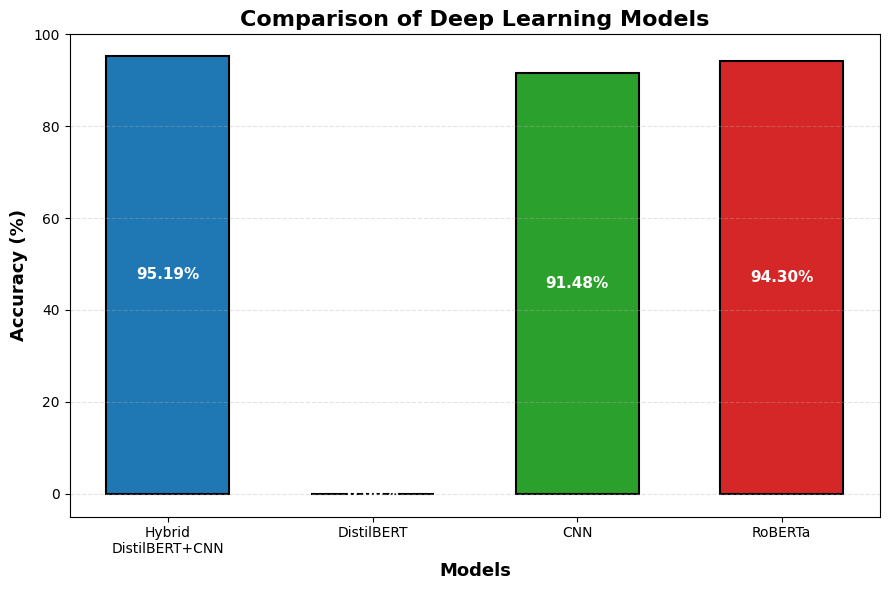

In [22]:
import matplotlib.pyplot as plt


models = [
    "Hybrid\nDistilBERT+CNN",
    "DistilBERT",
    "CNN",
    "RoBERTa"
]

accuracies = [
    hybrid_acc,
    distilbert_acc,
    cnn_acc,
    roberta_acc
]

colors = [
    "#1f77b4",   # Blue
    "#ff7f0e",   # Orange
    "#2ca02c",   # Green
    "#d62728"    # Red
]

plt.figure(figsize=(9,6))

bars = plt.bar(
    models,
    accuracies,
    color=colors,
    edgecolor="black",
    linewidth=1.5,
    width=0.6
)

plt.title("Comparison of Deep Learning Models", fontsize=16, fontweight="bold")
plt.xlabel("Models", fontsize=13, fontweight="bold")
plt.ylabel("Accuracy (%)", fontsize=13, fontweight="bold")

# Dynamic y-axis
plt.ylim(min(accuracies)-5, 100)

plt.grid(axis='y', linestyle='--', alpha=0.35)

# Accuracy value in the middle of each bar
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height/2,
        f"{height:.2f}%",
        ha='center',
        va='center',
        fontsize=11,
        fontweight='bold',
        color='white'
    )

plt.tight_layout()
plt.show()